In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [32]:
df = pd.read_csv("Mall_Customers.csv")

In [33]:
df.shape

(200, 5)

In [34]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [35]:
df.drop('CustomerID', axis=1, inplace=True)
df['Genre']=df['Genre'].map({'Male':1,'Female':0})
df.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Genre                   200 non-null    int64
 1   Age                     200 non-null    int64
 2   Annual Income (k$)      200 non-null    int64
 3   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4)
memory usage: 6.4 KB


In [37]:
df.isna().sum()

Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


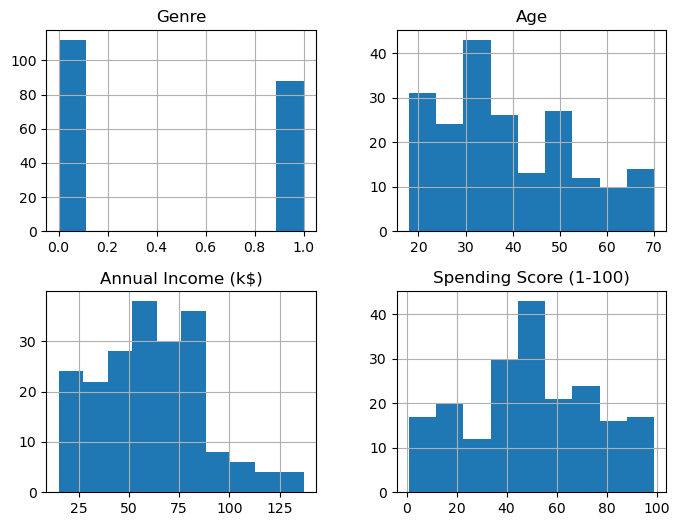

In [38]:
df.select_dtypes(include='number').hist(bins='auto', figsize=(8,6))
df.head()

Visualize how the random initialization looks

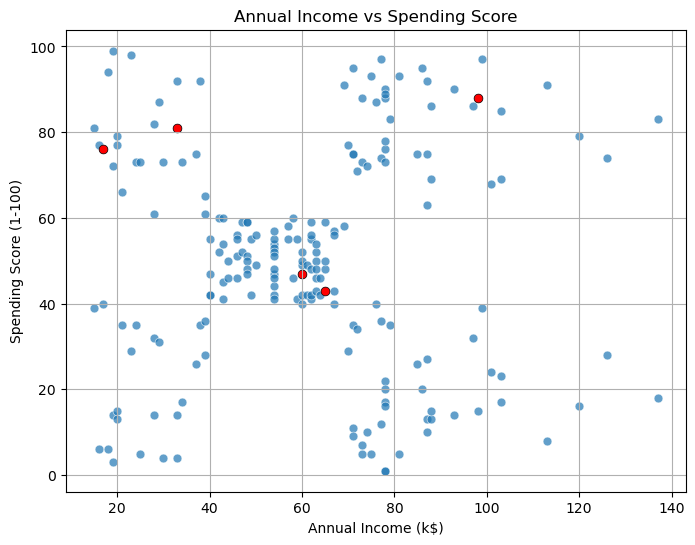

In [39]:
# EDA: simple scatter of Annual Income vs Spending Score
xcol = 'Annual Income (k$)'
ycol = 'Spending Score (1-100)'
plt.figure(figsize=(8,6))
plt.scatter(df[xcol], df[ycol], color='C0', s=40, alpha=0.7, edgecolors='w', linewidth=0.5)

# pick 5 random points to highlight
highlight = df.sample(n=5, random_state=40)
plt.scatter(highlight[xcol], highlight[ycol], color='red', s=40, edgecolors='k', linewidth=0.5, label='Highlighted')
plt.xlabel(xcol)
plt.ylabel(ycol)
plt.title('Annual Income vs Spending Score')
plt.grid(True)
plt.show()

# k-means Algorithm 

“K-Means alternates between assigning points to the nearest centroid and recomputing centroids as the mean of assigned points, stopping when centroid movement falls below a threshold or max iterations are reached.”

1. Initialize centroids

    1.1 Randomly select k data points from the dataset  
    1.2 Set these points as the initial centroids

2. For each iteration (up to max epochs)

    2.1 Assignment step

        2.1.1 For each data point, compute its distance to all centroids  
        2.1.2 Assign the point to the nearest centroid

    2.2 Update step

        2.2.1 For each cluster, sum all assigned data points and count them  
        2.2.2 Compute the new centroid as the mean of assigned points  
        2.2.3 If a cluster has no assigned points, reinitialize its centroid randomly

    2.3 Compute inertia

        2.3.1 Compute the total sum of squared distances between each point and its assigned centroid

    2.4 Check convergence

        2.4.1 Measure centroid movement between successive iterations  
        2.4.2 If the movement is below a threshold, stop the algorithm

    2.5 Update centroids

        2.5.1 Replace old centroids with the newly computed centroids

For a vector

x = [x₁, x₂, …, xₙ]

The Euclidean norm (L2 norm) (np.linalg.norm(x)) is defined as:

||x||₂ = √(x₁² + x₂² + … + xₙ²)

In [40]:
def k_means(X,k,max_epochs=100,epsilon=1e-5):
    X=np.array(X)
    m, n = X.shape

    # 1. Initialize centroids randomly from data points
    indices = np.random.choice(m, k, replace=False) # chooses each value from 0 to m-1 in shape (k,)
    centroids = X[indices]          # (k, n)

    for epoch in range(max_epochs):

        # 2.1 Assign all m points to their nearest centroid (respective clusters)
        labels=np.zeros(m,dtype=int)  # (m,)
        for i in range(m):
            min_dist=float('inf')
           
            for j in range(k):
                dist=np.linalg.norm(X[i]-centroids[j])
                if dist<min_dist:
                    min_dist=dist
                    labels[i]=j

        # 2.2 Update new centroids as mean of assigned points
        new_centroids = np.zeros((k, n))
        # Count points in each cluster
        each_cluster_pointscount = np.zeros(k)
        for i in range(m):
            new_centroids[labels[i]] += X[i]
            each_cluster_pointscount[labels[i]] += 1

        for i in range(k):
            # Handle empty clusters by reinitializing to a random data point
            if each_cluster_pointscount[i] == 0:
                new_centroids[i] = X[np.random.choice(m)]
            else:
                new_centroids[i] /= each_cluster_pointscount[i]
                

        # 2.3 Compute inertia (WCSS –> Within-Cluster Sum of Squares)
        # centroids shape: (k, n)
        # labels shape: (m,)    
        # centroids[labels] shape: (m, n) I.M.P. to understand
        inertia = np.sum((X - new_centroids[labels]) ** 2)
        # print(f"Epoch {epoch}: Inertia = {inertia}")


        # 2.4 Check convergence -> Frobenius norm (L2 on whole matrix) (we can also use, max centriod shift / all centroid shift)
        shift = np.linalg.norm(new_centroids - centroids)
        if shift < epsilon:
            print(f"Converged in {epoch} epochs due to shift < epsilon with interia: {inertia}")
            break

        if epoch == max_epochs - 1:
            print(f"Reached max epochs: {max_epochs} with interia: {inertia}")

        
        # 2.5 final centroid update
        centroids = new_centroids

    # In K-means, returning centriods is sufficient, but for our ease we return labels and inertia too 
    # both these parameters can be calculated outside too
    return centroids, labels, inertia


#.

Running k-means algo one time with random initialization

Visualize how the centroids end up after applying k-means algo  
Better but not best

Converged in 5 epochs due to shift < epsilon with interia: 79346.99372582373


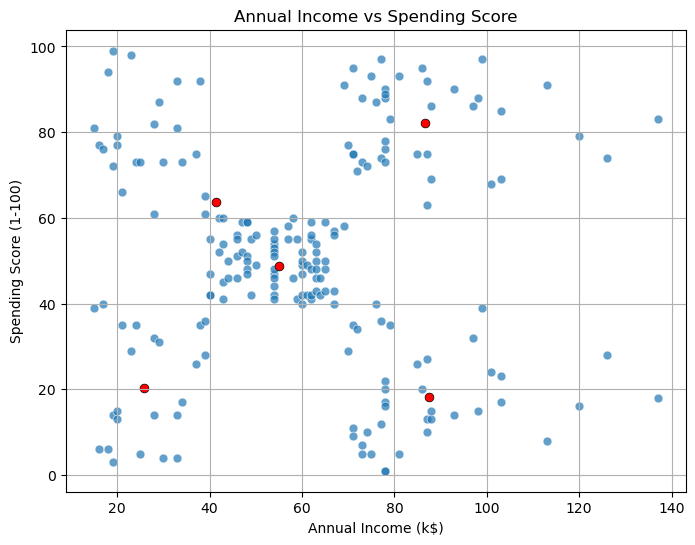

In [41]:
centroids, labels, inertia = k_means(df,5)

# EDA: simple scatter of Annual Income vs Spending Score
xcol = 'Annual Income (k$)'
ycol = 'Spending Score (1-100)'
plt.figure(figsize=(8,6))
plt.scatter(df[xcol], df[ycol], color='C0', s=40, alpha=0.7, edgecolors='w', linewidth=0.5)

# pick 5 random points to highlight
highlight = pd.DataFrame(centroids, columns=df.columns)
plt.scatter(highlight[xcol], highlight[ycol], color='red', s=40, edgecolors='k', linewidth=0.5, label='Highlighted')
plt.xlabel(xcol)
plt.ylabel(ycol)
plt.title('Annual Income vs Spending Score')
plt.grid(True)
plt.show()

Above figure clearly shows, k-means algo is very sensitive to centroid initialization,

If centroids are badly initialized, clusters are learned poorly.

To overcome this, we have to run k-means algo 50-100 times, so to choose the best learned clusters among all runs (Min Inertia)

# Running k-means 50 times i.e. 50 random initializations 

In [42]:
best_inertia = float('inf')
best_centroids = None
best_labels = None

n_runs = 50

for run in range(n_runs):
    centroids, labels, inertia = k_means(df, k=5, max_epochs=100)
    print(f"Run {run}, Inertia = {inertia:.2f}")

    if inertia < best_inertia:
        best_inertia = inertia
        best_centroids = centroids
        best_labels = labels
        best_run = run

print(f"Best Inertia: {best_inertia} achieved in Best Run: {best_run}")

Converged in 9 epochs due to shift < epsilon with interia: 82686.02774127264
Run 0, Inertia = 82686.03
Converged in 15 epochs due to shift < epsilon with interia: 82686.02774127264
Run 1, Inertia = 82686.03
Converged in 10 epochs due to shift < epsilon with interia: 75542.77371510219
Run 2, Inertia = 75542.77
Converged in 9 epochs due to shift < epsilon with interia: 75528.58656469136
Run 3, Inertia = 75528.59
Converged in 8 epochs due to shift < epsilon with interia: 75542.77371510219
Run 4, Inertia = 75542.77
Converged in 9 epochs due to shift < epsilon with interia: 79325.58616149588
Run 5, Inertia = 79325.59
Converged in 8 epochs due to shift < epsilon with interia: 85679.73322625125
Run 6, Inertia = 85679.73
Converged in 10 epochs due to shift < epsilon with interia: 75542.77371510219
Run 7, Inertia = 75542.77
Converged in 4 epochs due to shift < epsilon with interia: 79325.58616149588
Run 8, Inertia = 79325.59
Converged in 12 epochs due to shift < epsilon with interia: 82657.0547

#.

Visualize the best learned centroids out of 50 runs i.e. 50 random initializations

compare with old centroids we got with only one time run of k-means  
New centroids are perfect BEST

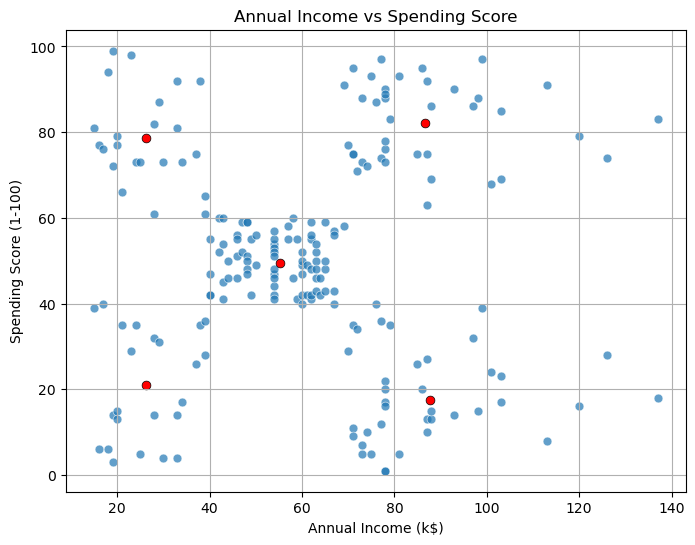

In [43]:
# EDA: simple scatter of Annual Income vs Spending Score
xcol = 'Annual Income (k$)'
ycol = 'Spending Score (1-100)'
plt.figure(figsize=(8,6))
plt.scatter(df[xcol], df[ycol], color='C0', s=40, alpha=0.7, edgecolors='w', linewidth=0.5)

# pick 5 random points to highlight
highlight = pd.DataFrame(best_centroids, columns=df.columns)
plt.scatter(highlight[xcol], highlight[ycol], color='red', s=40, edgecolors='k', linewidth=0.5, label='Highlighted')
plt.xlabel(xcol)
plt.ylabel(ycol)
plt.title('Annual Income vs Spending Score')
plt.grid(True)
plt.show()

# Knowledge ++

Elbow method  (to find optimal K)  

Run K-Means for different values of K  
Compute inertia (WCSS) for each K  
Look for a point where inertia stops decreasing sharply  
→ that point is the elbow (optimal K)  

Inertia always decreases as K increases  
Elbow is sometimes not very sharp  
We can run k-means multiple times also for each K, but one time is also sufficient, gives us intuition graphically

Converged in 13 epochs due to shift < epsilon with interia: 212889.44245524297
Converged in 16 epochs due to shift < epsilon with interia: 154627.55913714768
Converged in 6 epochs due to shift < epsilon with interia: 104414.67534220166
Converged in 2 epochs due to shift < epsilon with interia: 75412.59682443162
Converged in 8 epochs due to shift < epsilon with interia: 72177.72439005438
Converged in 9 epochs due to shift < epsilon with interia: 74037.40412356154
Converged in 6 epochs due to shift < epsilon with interia: 51900.88219039097
Converged in 5 epochs due to shift < epsilon with interia: 52709.509410752085


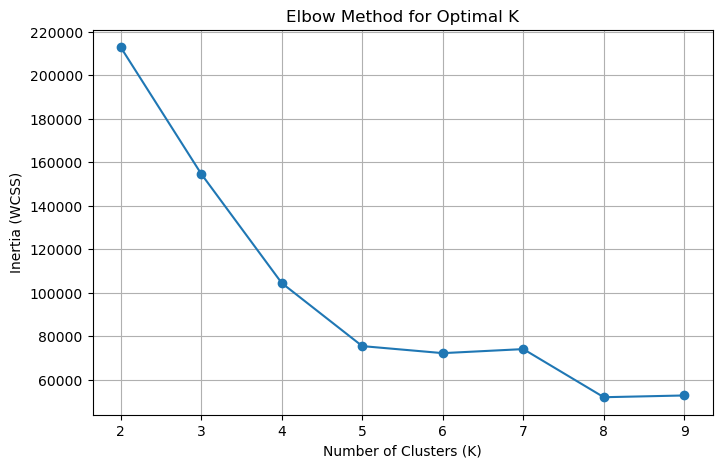

In [44]:
def elbow_method(X, k_range, max_epochs=100):
    inertias = []

    for k in k_range:
        _, _, inertia = k_means(X, k, max_epochs=max_epochs)
        inertias.append(inertia)

    return inertias

k_range = range(2, 10)

inertias = elbow_method(df,k_range)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for Optimal K")
plt.grid(True)
plt.show()

# Knowledge ++

Silhouette Score  
“Silhouette score measures how well a point fits within its cluster compared to other clusters.   
It ranges from −1 to 1 and is ideal for evaluating unsupervised clustering quality.”

For each data point xi:  
a(i) intra-cluster distance = Average distance from xi to all other points in the same cluster  
b(i) inter-cluster distance = Minimum of the average distances from xi to points in the other clusters  
b(i) is the MINIMUM of the average distances to all OTHER clusters 

Think of silhouette as asking:  
“Is this point closer to its own cluster
or to the nearest other cluster that might steal it?”

Silhouette value for point i:  
s(i) = ( b(i) − a(i) ) /  max( a(i), b(i) )

Overall Silhouette Score = Average of s(i) for all data points

Interpretation:  
• s(i) close to +1 → Point is well clustered
• s(i) close to 0 → Point lies between clusters
• s(i) close to −1 → Point is likely in the wrong cluster

Silhouette is O(m²) → slow for large datasets

Use it for evaluation, not inside training loop

In [45]:
def silhouette_with_distance_matrix(X, labels):
    X=np.array(X)
    m = X.shape[0]
    D = np.zeros((m, m))
    for i in range(m):
        for j in range(i+1, m):
            dist = np.linalg.norm(X[i] - X[j])
            D[i, j] = dist
            D[j, i] = dist

    s_total = 0.0
    k = len(set(labels))

    for i in range(m):
        a_sum = 0.0
        a_count = 0

        b_sum = np.zeros(k)
        b_count = np.zeros(k)

        for j in range(m):
            if i == j:
                continue

            if labels[j] == labels[i]:
                a_sum += D[i, j]
                a_count += 1
            else:
                c = labels[j]
                b_sum[c] += D[i, j]
                b_count[c] += 1

        a_i = a_sum / a_count if a_count > 0 else 0.0

        # Below part is doing three things at once:
        # Ignoring own cluster
        # Ignoring empty clusters
        # Taking the minimum average distance from other clusters

        b_i = np.inf
        for x in range(k):
            if x == labels[i] or b_count[x] == 0:
                continue
            b_i = min(b_i, b_sum[x] / b_count[x])

        s_total += (b_i - a_i) / max(a_i, b_i)

    return s_total / m




silhouette_score = silhouette_with_distance_matrix(df,best_labels)
silhouette_score

0.44406692047430096

For K-Means, “prediction” simply means:  
👉 assign the new point to the nearest learned centroid.

“Leaving an empty cluster unchanged is incorrect because it effectively reduces the number of active clusters while still pretending to optimize for K. This breaks the K-Means objective, distorts evaluation metrics, and leads to dead centroids. The correct approach is to reinitialize the empty centroid to ensure all K clusters actively participate.”

If you “leave it as it is”:  
Its centroid never moves  
No point is ever assigned to it again  
It becomes a dead centroid  
So effectively, your algorithm is now behaving like K−1 clusters, but pretending it has K.  
That’s the core problem.  
 